# Where do LLMs fail when generating code?
**Paper:** Wang et al. 2025 (ICSE) – Towards Understanding the Characteristics of Code Generation Errors Made by Large Language Models
**Data:** https://github.com/ma-labo/defects4codellm

**What is in the data:** Wrong solutions of **6 LLMs** (CodeGen, InCoder, GPT-3.5, GPT-4, SantaCoder, StarCoder) on the **HumanEval** benchmark (164 Python tasks). Each error is labelled by hand with a **semantic** type (what is wrong) and a **syntactic** type (where in the code), and comes with the wrong code and the correct code. ⚠️ Benchmark code, not real projects – we use it as an **error taxonomy for Q2 (what was wrong)**.

**One row of the main table =** one error in one LLM solution

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "..")          # to find common.py in the parent folder
from common import *

## 0. Get the data

In [2]:
root = get_repo("https://github.com/ma-labo/defects4codellm", "defects4codellm")

Data folder: ../../data/07_Wang_LLM_Code_Errors/defects4codellm


## 1. First look
### Files in the repository

In [3]:
list_files(root)

,file,size_MB
0,data/incoder-humaneval_error.csv,0.29
1,data/santacoder-humaneval_error.csv,0.26
2,data/codegen-humaneval_error.csv,0.19
3,data/starcoder-humaneval_error.csv,0.17
4,data/gpt-3.5-humaneval_error.csv,0.08
5,data/gpt-4-humaneval_error.csv,0.03


### Main table: the 6 files (one per LLM) put together

In [4]:
import glob
parts = []
for f in sorted(glob.glob(os.path.join(root, "data", "*-humaneval_error.csv"))):
    t = pd.read_csv(f); t["llm"] = os.path.basename(f).split("-humaneval")[0]; parts.append(t)
w = pd.concat(parts, ignore_index=True)
_ = overview(w.drop(columns=["Incorrect Code (Complete)", "Ground Truth Code (Complete)"]), "LLM code errors")

**LLM code errors** — **687 rows × 6 columns** (0.1 MB in memory)

*First 5 lines:*

,Error ID,Model,Task ID,Semantic Characteristics,Syntactic Characteristics,llm
0,1,CodeGen-16B,1,Ae1 Only comments,Bg2 Missing code block,codegen
1,2,CodeGen-16B,3,Af2 Missing multiple steps,Bg2 Missing code block,codegen
2,3,CodeGen-16B,5,Ae3 Wrong (logical) direction,Bg1 Incorrect code block,codegen
3,4,CodeGen-16B,6,Ae1 Only comments,Bg2 Missing code block,codegen
4,5,CodeGen-16B,10,Ac2 Undefined name,Bd1 Incorrect function name,codegen


*All columns:*

,column,type,missing_%,unique,example
0,Error ID,int64,0.0,687,1
1,Model,str,0.0,6,CodeGen-16B
2,Task ID,int64,0.0,150,1
3,Semantic Characteristics,str,0.0,13,Ae1 Only comments
4,Syntactic Characteristics,str,0.0,14,Bg2 Missing code block
5,llm,str,0.0,6,codegen


## 2. Data-science view
### Size

In [5]:
w["llm"] = w["llm"].replace({"gpt-3.5": "GPT-3.5", "gpt-4": "GPT-4", "codegen": "CodeGen-16B", "incoder": "InCoder-1.3B", "santacoder": "SantaCoder", "starcoder": "StarCoder"})
lines = lambda s: s.fillna("").astype(str).str.count("\n") + 1
w["wrong_lines"], w["correct_lines"] = lines(w["Incorrect Code (Complete)"]), lines(w["Ground Truth Code (Complete)"])
w["line_diff"] = w["wrong_lines"] - w["correct_lines"]
print("Error rows:", len(w), "| tasks:", w["Task ID"].nunique(), "| LLMs:", w.llm.nunique())
print("Language: Python (HumanEval) | Dates: models from 2022-2023, paper 2024 (ICSE 2025)")

Error rows: 687 | tasks: 150 | LLMs: 6
Language: Python (HumanEval) | Dates: models from 2022-2023, paper 2024 (ICSE 2025)


### Numbers per LLM

In [6]:
sem = w["Semantic Characteristics"].astype(str).str.split(",").explode().str.strip()
per_agent = w.groupby("llm").agg(errors=("Task ID", "size"), tasks_failed=("Task ID", "nunique"), median_wrong_lines=("wrong_lines", "median")).sort_values("errors", ascending=False)
save_table(per_agent.reset_index(), "per_agent")
per_agent

,errors,tasks_failed,median_wrong_lines
llm,,,
InCoder-1.3B,182,144,17.0
SantaCoder,181,139,15.0
CodeGen-16B,129,110,16.0
StarCoder,123,104,14.0
GPT-3.5,52,42,20.5
GPT-4,20,18,25.0


### How the LLM is involved
The LLM **writes the whole solution** of a HumanEval task. The researchers compare it with the correct solution and label the errors by hand. No developer and no later fix.

In [7]:
summary_card("Wang et al. 2025", "one error in an LLM solution", len(w), "HumanEval (164 tasks)", "2022-2023 models",
             "ICSE 2025", ", ".join(per_agent.index), "LLM writes the solution; researchers label the errors", "n/a (error taxonomy, correct code given)")

,
paper,Wang et al. 2025
unit (1 row =),one error in an LLM solution
rows,687
repos,HumanEval (164 tasks)
first date,2022-2023 models
latest date,ICSE 2025
agents,"InCoder-1.3B, SantaCoder, CodeGen-16B, StarCoder, GPT-3...."
how the agent is involved,LLM writes the solution; researchers label the errors
fixes of AI code,"n/a (error taxonomy, correct code given)"


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Wang et al. 2025,one error in an LLM solution,687,HumanEval (164 tasks),2022-2023 models,ICSE 2025,"InCoder-1.3B, SantaCoder, CodeGen-16B, StarCoder, GPT-3....",LLM writes the solution; researchers label the errors,"n/a (error taxonomy, correct code given)"


## 3. Charts
### Chart 1 · Semantic error types (what is wrong)

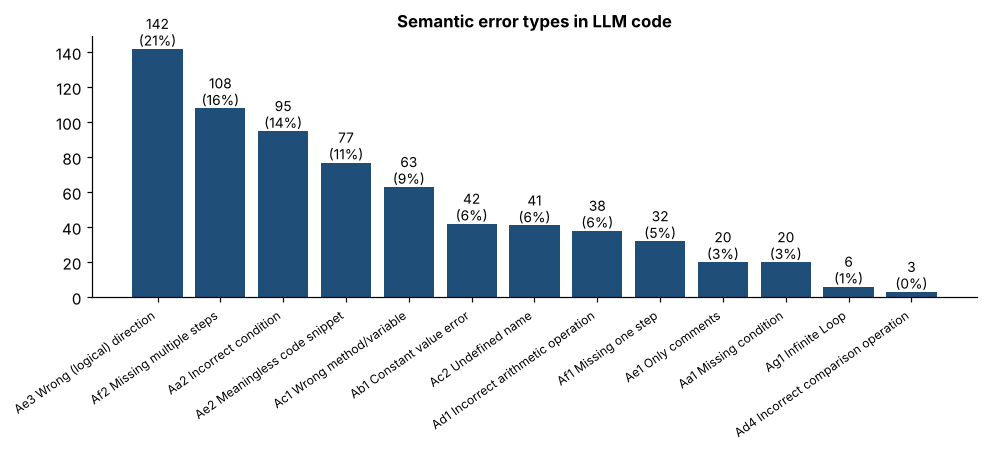

*Exact numbers – Semantic error types in LLM code*

,number,%
Semantic Characteristics,,
Ae3 Wrong (logical) direction,142.0,20.7
Af2 Missing multiple steps,108.0,15.7
Aa2 Incorrect condition,95.0,13.8
Ae2 Meaningless code snippet,77.0,11.2
Ac1 Wrong method/variable,63.0,9.2
Ab1 Constant value error,42.0,6.1
Ac2 Undefined name,41.0,6.0
Ad1 Incorrect arithmetic operation,38.0,5.5
Af1 Missing one step,32.0,4.7


In [8]:
bar(sem.value_counts().head(13), "Semantic error types in LLM code", "1_semantic_errors.png", horizontal=True, pct=True)

### Chart 2 · Errors per LLM

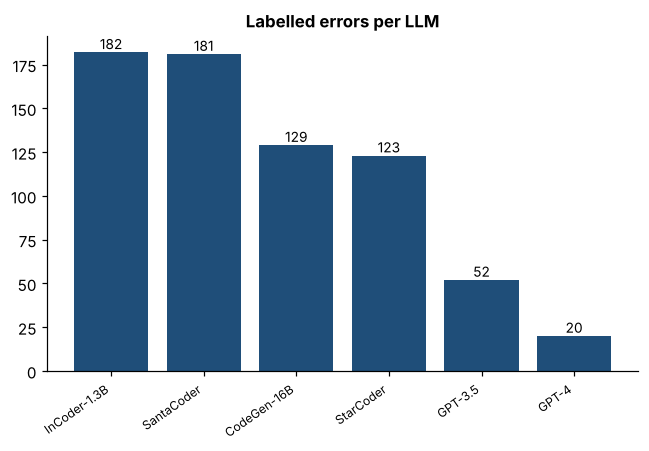

*Exact numbers – Labelled errors per LLM*

,number,%
llm,,
InCoder-1.3B,182.0,26.5
SantaCoder,181.0,26.3
CodeGen-16B,129.0,18.8
StarCoder,123.0,17.9
GPT-3.5,52.0,7.6
GPT-4,20.0,2.9
TOTAL,687.0,100.0


In [9]:
bar(per_agent["errors"], "Labelled errors per LLM", "2_errors_per_llm.png", horizontal=True)

### Chart 3 · Syntactic error types (where in the code)

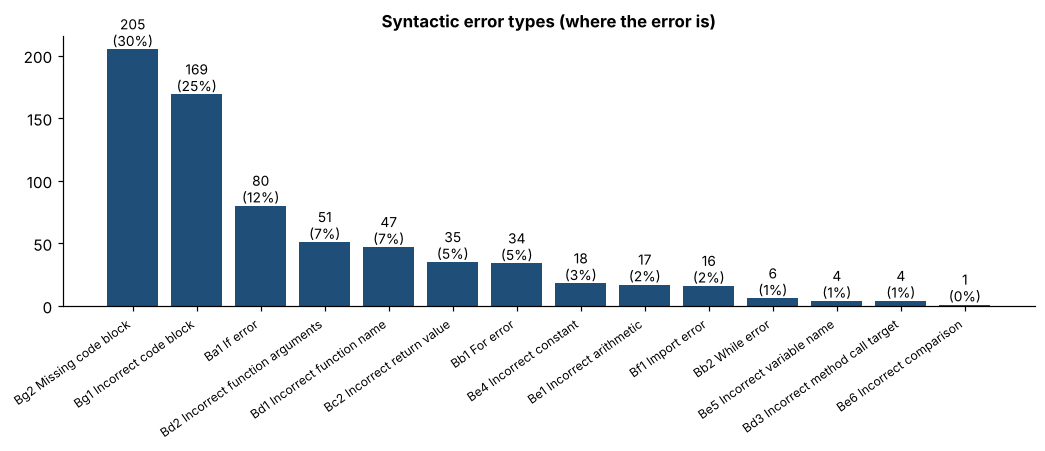

*Exact numbers – Syntactic error types (where the error is)*

,number,%
Syntactic Characteristics,,
Bg2 Missing code block,205.0,29.8
Bg1 Incorrect code block,169.0,24.6
Ba1 If error,80.0,11.6
Bd2 Incorrect function arguments,51.0,7.4
Bd1 Incorrect function name,47.0,6.8
Bc2 Incorrect return value,35.0,5.1
Bb1 For error,34.0,4.9
Be4 Incorrect constant,18.0,2.6
Be1 Incorrect arithmetic,17.0,2.5


In [10]:
syn = w["Syntactic Characteristics"].astype(str).str.split(",").explode().str.strip()
bar(syn.value_counts().head(14), "Syntactic error types (where the error is)", "3_syntactic_errors.png", horizontal=True, pct=True)

### Chart 4 · Size of the wrong code vs the correct code

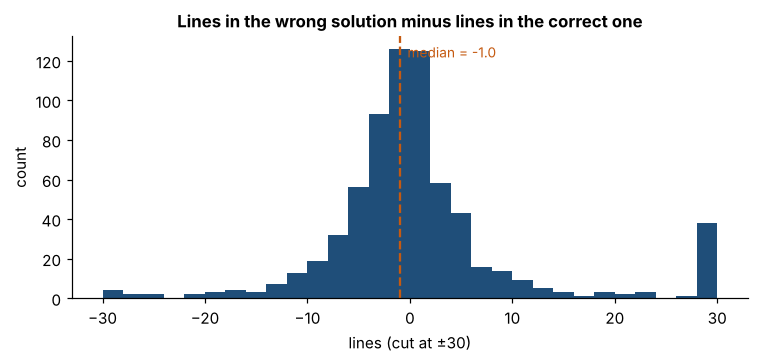

*Exact numbers – Lines in the wrong solution minus lines in the correct one*

,count,mean,std,min,25%,median,75%,max
lines (cut at ±30),687.0,0.38,9.65,-30.0,-4.0,-1.0,2.0,30.0


In [11]:
hist(w["line_diff"].clip(-30, 30), "Lines in the wrong solution minus lines in the correct one", "4_line_diff.png", "lines (cut at ±30)", bins=30)

## 4. Final figure (the 4 charts on one page)

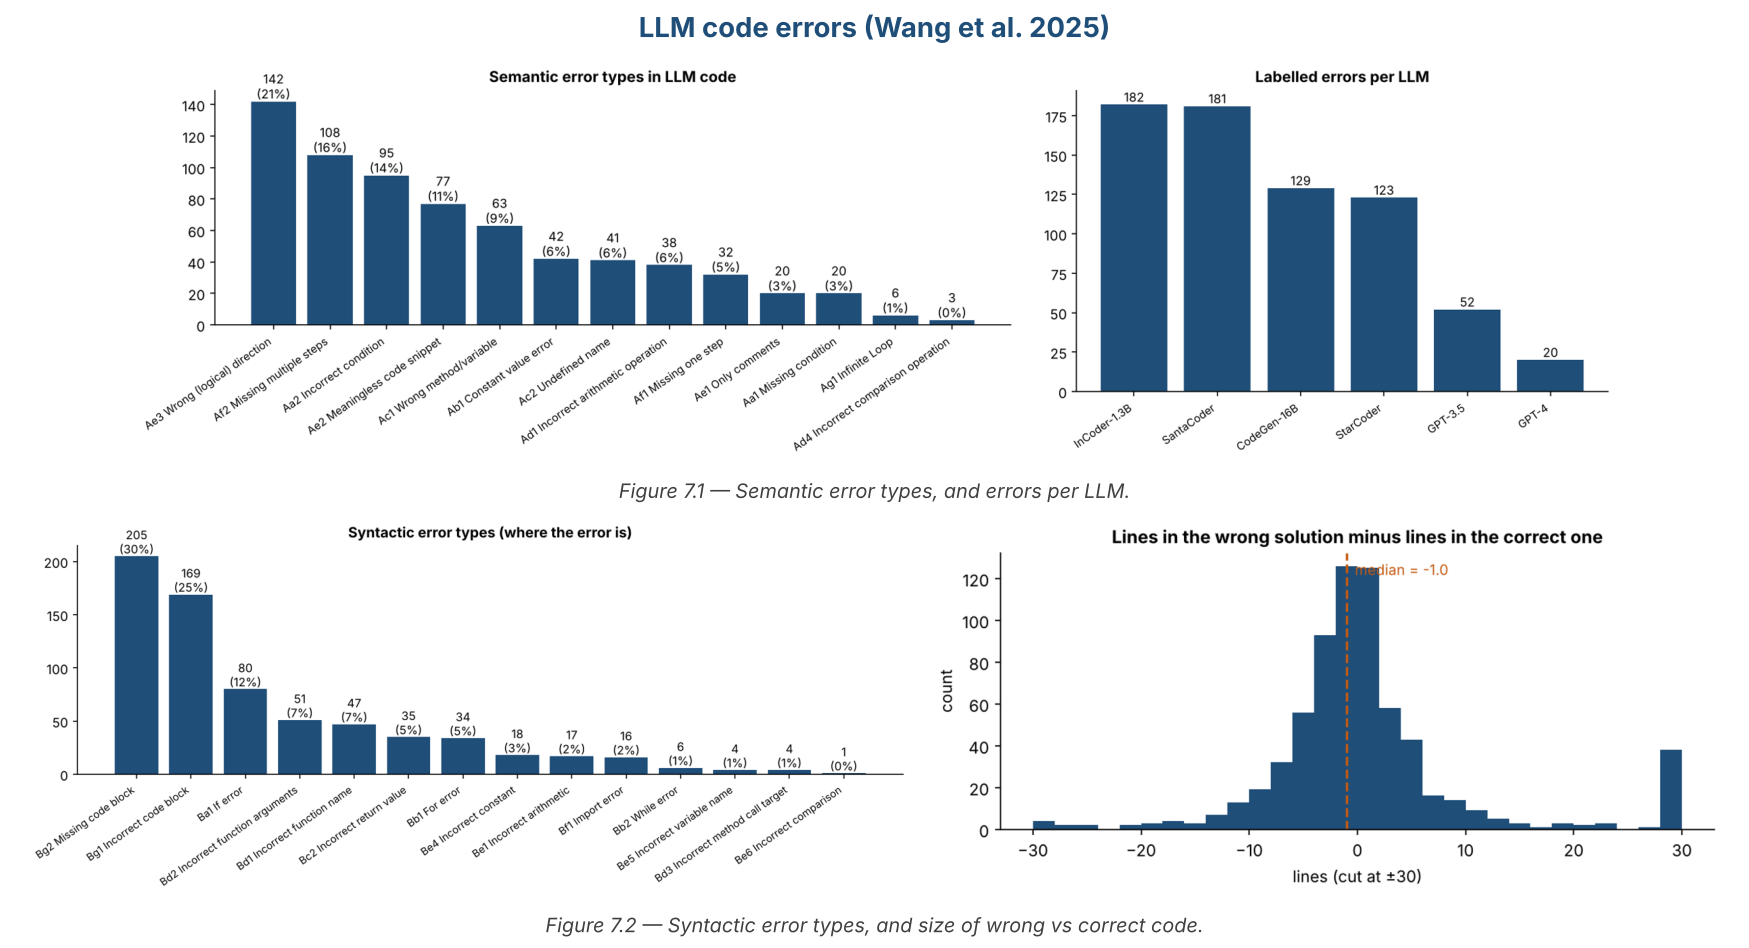

In [12]:
final_figure(7, "LLM code errors (Wang et al. 2025)",
             "Semantic error types, and errors per LLM.",
             "Syntactic error types, and size of wrong vs correct code.")

## 5. Fixes
No real-world fixes (benchmark). Nothing is added to the final dataset; the **error taxonomy** is reused for our Q2.